# Разведочный анализ данных (EDA)
>Задача – провести анализ данных о клиентах и их кредитной истории в банке.

На основе предоставленных данных необходимо оценить кредитные риски клиентов, выявить аномалии в данных и предложить рекомендации для улучшения работы банка с клиентами.

Данные сформированы на основе датасета из [Kaggle-соревнования](https://www.kaggle.com/datasets/ranadeep/credit-risk-dataset/data):

``` text
data/LoansData.csv – информация о клиентах банка.
```
##### Описание данных:
    • `id` – Идентификатор записи кредитной истории;
    • `member_id` – Идентификатор заёмщика;
    • `loan_amnt` – Указанная сумма кредита;
    • `funded_amnt` – Сумма кредита;
    • `term` – Срок кредита;
    • `int_rate` – Процентная ставка по кредиту;
    • `installment` – Ежемесячный платёж по кредиту;
    • `grade` – Рейтинг кредита;
    • `sub_grade` – Детализированный рейтинг кредита;
    • `emp_title` – Должность заёмщика;
    • `Emp_length` – Трудовой стаж в годах;
    • `home_ownership` – Статус домовладения;
    • `annual_inc` – Годовой доход заёмщика;
    • `verification_status` – Флаг подтверждения источника дохода;
    • `issue_d` – Месяц выдачи кредита;
    • `loan_status` – Текущее состояние кредита;
    • `pymnt_plan` – Флаг наличия плана платежей;
    • `desc` – Описание кредита, предоставленное заёмщиком;
    • `purpose` – Цель кредита;
    • `zip_code` – Почтовый индекс заёмщика;
    • `addr_state` – Штат заёмщика;
    • `dti` – Сумма платежей по кредиту к доходу;
    • `delinq_2yrs` – Количество просрочек более чем на 30 дней в кредитной истории заёмщика за последние 2 года;
    • `earliest_cr_line` – Месяц, в котором была открыта самая ранняя заявленная заёмщиком кредитная линия;
    • `inq_last_6mths` – Количество заявок на кредитные продукты за последние 6 месяцев;
    • `open_acc` – Количество открытых кредитов;
    • `total_acc` – Общее количество кредитов;
    • `out_prncp` – Отношение непогашенной суммы к общей сумме задолженности;
    • `total_pymnt` – Платежи по долгам к общей сумме задолженности;
    • `total_rec_prncp` – Выплаченная сумма из общей задолженности;
    • `total_rec_int` – Выплаченные проценты общей задолженности;
    • `total_rec_late_fee` – Просроченные платежи на сегодняшний день общей задолженности;
    • `last_pymnt_d` – Флаг получения платежа в прошлом месяце;
    • `last_pymnt_amnt` – Сумма последнего платежа;
    • `next_pymnt_d` – Дата следующего платежа;
    • `mths_since_last_major_derog` – Количество месяцев с последней просрочки 90+ или ухудшения рейтинга;
    • `policy_code` – Флаг наличия специфичных продуктов;
    • `application_type` – Тип кредитной заявки (индивидуальная/совместная);
    • `annual_inc_joint` – Совокупный годовой доход созаёмщиков;
    • `dti_joint`  – Сумма платежей по кредитам к доходу созаёмщиков;
    • `acc_now_delinq` – Количество кредитов, по которым заёмщик в настоящее время имеет просроченную задолженность;
    • `tot_coll_amt` – Общая сумма взыскания при наличии;
    • `tot_cur_bal` – Общий текущий баланс по всем счетам;
    • `open_acc_6m` – Количество открытых кредитов за последние 6 месяцев;
    • `open_il_6m` – Количество активных сделок рассрочки;
    • `open_il_12m` – Количество счетов рассрочки, открытых за последние 12 месяцев;
    • `open_il_24m` – Количество счетов рассрочки, открытых за последние 24 месяца;
    • `mths_since_rcnt_il` – Месяцев с момента открытия последних счетов рассрочки;
    • `inq_last_12m` – Количество заявок на кредитные продукты за последние 12 месяцев.

Импортируем библиотеки

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

### 1. Загрузи данные из CSV файла в pd.DataFrame.

In [2]:
loans = pd.read_csv("../data/loan.csv", low_memory=False)
loans.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,1077501,1296599,5000.0,5000.0,4975.0,36 months,10.65,162.87,B,B2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1077430,1314167,2500.0,2500.0,2500.0,60 months,15.27,59.83,C,C4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1077175,1313524,2400.0,2400.0,2400.0,36 months,15.96,84.33,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1076863,1277178,10000.0,10000.0,10000.0,36 months,13.49,339.31,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1075358,1311748,3000.0,3000.0,3000.0,60 months,12.69,67.79,B,B5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
loans_copy = loans.copy()

### 2. Определи доли для различных групп заявок (группа лежит в поле application_type)

In [4]:
loans["application_type"].value_counts()

application_type
INDIVIDUAL    886868
JOINT            511
Name: count, dtype: int64

In [5]:
print("Доля группы INDIVIDUAL:", round(loans["application_type"].value_counts().iloc[0] / loans["application_type"].count() * 100, 2), "%")
print("Доля группы JOINT:", round(loans["application_type"].value_counts().iloc[1] / loans["application_type"].count() * 100, 2), "%")

Доля группы INDIVIDUAL: 99.94 %
Доля группы JOINT: 0.06 %


### 3. Проанализируй количество пустых значений для каждой из групп заявок:
- 3.1. Проанализируй общее количество записей в группах: удали из выборки записи той группы, чья доля меньше 5% от общего количества записей.
- 3.2. Проанализируй заполняемость полей: удали поля, у которых доля пустых значений на всей выборке превышает 20%.

Вопрос: У какого поля оказалась максимальная доля пустых значений и какова эта доля?

In [6]:
print((loans.isna().mean() * 100).sort_values(ascending=False).head())

dti_joint                    99.942640
annual_inc_joint             99.942415
verification_status_joint    99.942415
il_util                      97.902024
mths_since_rcnt_il           97.654892
dtype: float64


_**Ответ на вопрос:**_ **dti_joint = 99.94%** 

Заявка по типу "JOINT" занимает 0.06% от всего датасета, следовательно, поля, предназначенные для заполнения этого типа заявки: `dti-joint`, `annual_inc_joint` и `verification_status_joint` будут пустыми для оставшегося 99.94% лога. По условию задачи избавляемся от типа заявки JOINT, чья доля меньше 5%.

##### 3.1. Удаляем записи группы заявок с характеристикой "JOINT".

In [7]:
loans = loans[loans["application_type"] != "JOINT"]

##### 3.2. Находим поля, где доля пустых значений больше 20%

In [8]:
cols_to_check = loans.columns[loans.isna().mean() * 100 > 20]

Удаляем найденные выше поля с пустыми значениями

In [9]:
loans = loans.drop(columns=cols_to_check)

### 4. Проанализируй количество дубликатов в оставшихся полях:
- 4.1. Укажи, как часто встречается уникальное значение в поле для ‘grade’, ‘home_ownership’, ‘verification_status’, ‘pymnt_plan’.
- 4.2. Проанализируй оставшиеся столбцы. Удали поля, у которых количество уникальных значений меньше 10 и распределение значений сильно смещено (доля одного значения от общего числа составляет >80%).

Вопрос: У какого поля наименьшее число уникальных значений?

In [10]:
cols = ["grade", "home_ownership", "verification_status", "pymnt_plan"]

In [11]:
print(loans[cols].nunique().sort_values())

pymnt_plan             2
verification_status    3
home_ownership         6
grade                  7
dtype: int64


In [12]:
for col in cols:
   print(loans[col].value_counts())
   print()

grade
B    254433
C    245717
A    148184
D    139419
E     70614
F     23022
G      5479
Name: count, dtype: int64

home_ownership
MORTGAGE    443203
RENT        355995
OWN          87435
OTHER          182
NONE            50
ANY              3
Name: count, dtype: int64

verification_status
Source Verified    329424
Verified           290810
Not Verified       266634
Name: count, dtype: int64

pymnt_plan
n    886858
y        10
Name: count, dtype: int64



_**Ответ на вопрос:**_ **pymnt_plan** с двумя значениями = **y** и **n**.

Вопрос: От каких полей ты избавился на этапе проверки на дубликаты?

In [13]:
cols_to_drop = []

for col in loans.columns:
    if loans[col].nunique() < 10:
        max_share = loans[col].value_counts(normalize=True).max()
        if max_share > 0.8:
            cols_to_drop.append(col)

print("Столбцы на удаление:", cols_to_drop)

Столбцы на удаление: ['pymnt_plan', 'policy_code', 'application_type', 'acc_now_delinq']


In [14]:
loans = loans.drop(columns=cols_to_drop)

### 5. Проанализируй числовые поля:
- 5.1. Построй  графики распределения значений (histplot) для 'loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'sub_grade', 'home_ownership';
- 5.2. Приведи основную статистику для поля ‘loan_amnt’. Укажи:

        - Максимальное и минимальное значения.
        - Среднее значение.
        - Медианное значение.
        - Стандартное отклонение.
        - Квантили уровня 1%, 5%, 95%, 99%.
- 5.3. Сделай вывод на основании полученных статистик.
>Например: низкое значение стандартного отклонения по сравнению со средним указывает на однородность сумм займов, а высокие или низкие квантили (1%, 5%, 95%, 99%) укажут на возможные экстремальные значения и выбросы.
- 5.4. Построй boxplot для полей ‘loan_amnt’, ‘installment’, ‘int_rate’. Визуально оцени, как распределены значения сумм кредита, ежемесячных платежей и процентных ставок у заёмщиков. Присутствуют ли значимые экстремальные значения и выбросы?
- 5.5. Оцени распределение числовых переменных относительно статуса займа (‘loan_status’). Построй графики boxplot для следующих полей:

        - ‘int_rate’.
        - ‘dti’.
        - ‘loan_amnt’.
- 5.6. Оцени, как эти показатели варьируются относительно разных статусов займов (например, выплаченные, дефолтные, просроченные и т. д.). Попытайся выявить тенденции (например, более высокие процентные ставки у дефолтных займов могут свидетельствовать о большем риске; отношение долга к доходу (dti) можно использовать для оценки уровня закредитованности клиентов, что также может коррелировать со статусом займа).
- 5.7. Построй график barplot для среднего значения ‘annual_inc’ по ‘loan_status’. Сделай вывод о форме распределения дохода заёмщика относительно статуса по его кредиту.
- 5.8. Оцени  корреляцию между полями ['int_rate', 'loan_amnt', 'total_pymnt', 'total_acc'].
- 5.9. Построй корреляционную матрицу (.corr()).
- 5.10. Укажи пару полей с наибольшим значением корреляции.
- 5.11. Построй график, описывающий взаимосвязь между этой парой полей. 

##### 5.1. Построим гистограммы для полей 'loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'sub_grade', 'home_ownership'

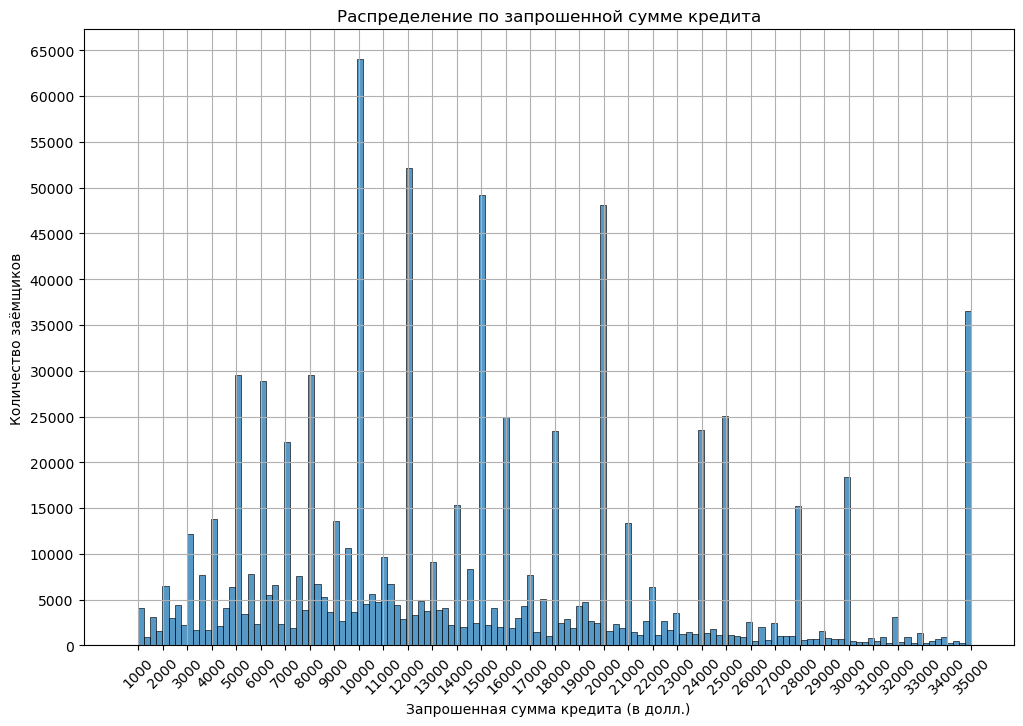

In [15]:
plt.figure(figsize=(12, 8))
sns.histplot(data=loans, x="loan_amnt")
plt.title("Распределение по запрошенной сумме кредита")
plt.xlabel("Запрошенная сумма кредита (в долл.)")
plt.xticks(np.arange(1000, 35001, 1000), rotation=45)
plt.ylabel("Количество заёмщиков")
plt.yticks(np.arange(0, 70000, 5000))
plt.grid()
plt.show()

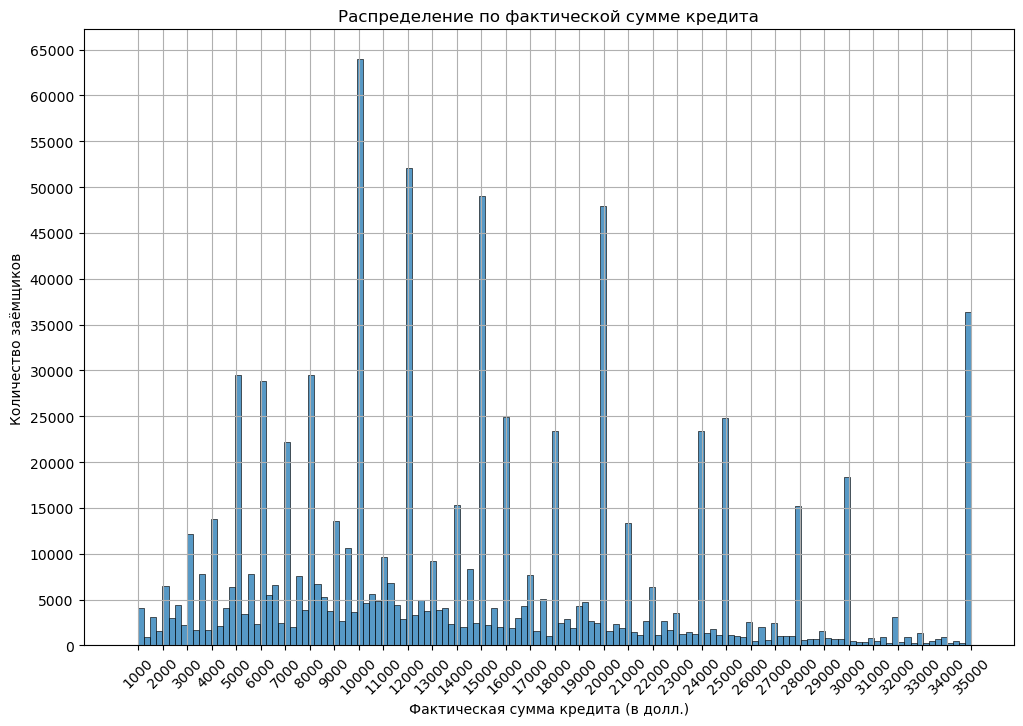

In [16]:
plt.figure(figsize=(12, 8))
sns.histplot(data=loans, x="funded_amnt")
plt.title("Распределение по фактической сумме кредита")
plt.xlabel("Фактическая сумма кредита (в долл.)")
plt.xticks(np.arange(1000, 35001, 1000), rotation=45)
plt.ylabel("Количество заёмщиков")
plt.yticks(np.arange(0, 70000, 5000))
plt.grid()
plt.show()

В двух графиках выше видна схожесть: первая тройка по сумме займа – $10000, $12000, $15000 – это говорит, что банк одобряет и выдаёт ту сумму кредита, которую запрашивал клиент.

Из графика можно узнать, что клиенты склонны запрашивать круглые суммы кредитов.

Среднее сумм кредита сосредоточено в диапазоне от $10000 до $20000.

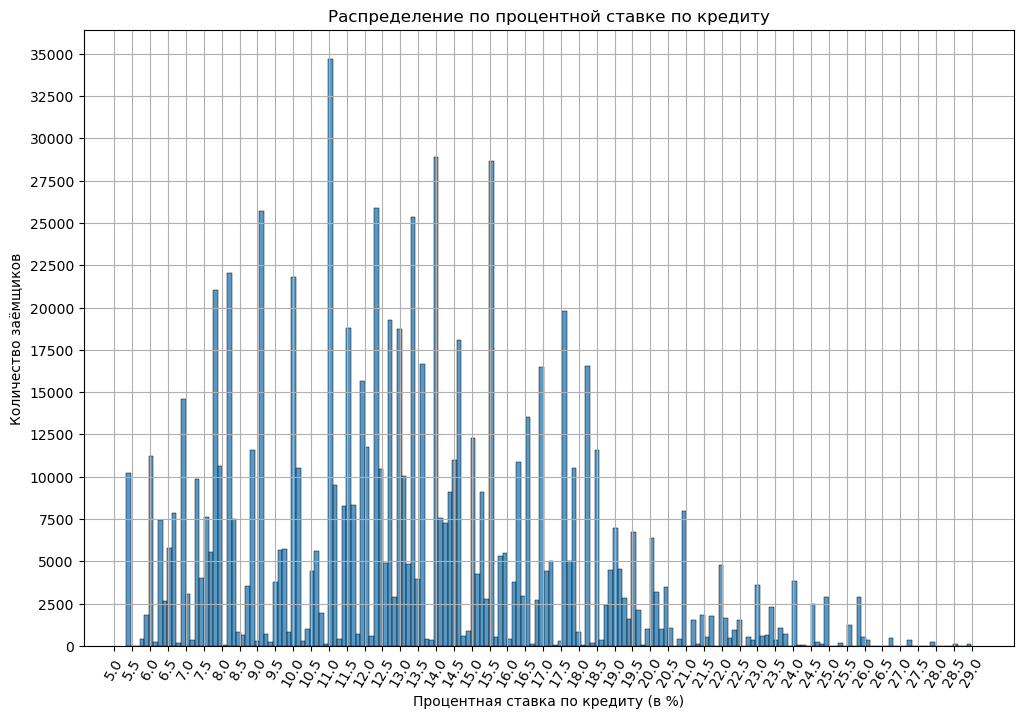

In [17]:
plt.figure(figsize=(12, 8))
sns.histplot(data=loans, x="int_rate")
plt.title("Распределение по процентной ставке по кредиту")
plt.xlabel("Процентная ставка по кредиту (в %)")
plt.xticks(np.arange(5, 29.5, 0.5), rotation=60)
plt.ylabel("Количество заёмщиков")
plt.yticks(np.arange(0, 35001, 2500))
plt.grid()
plt.show()

График напоминает нормальное распределение Гаусса со смещением влево: где видим хвост высоких процентных ставок, которые имеют редкий характер, скорее всего, для клиентов в низким кредитным рейтингом.

Больше всего выданы кредиты по ставке 11%, 14%, 15.5% – это середина отрисованного графика со смещением.

Возможно, банк предлагает клиентам стандартные тарифные планы или кредитные продукты с фиксированными ставками для основной массы клиентов.

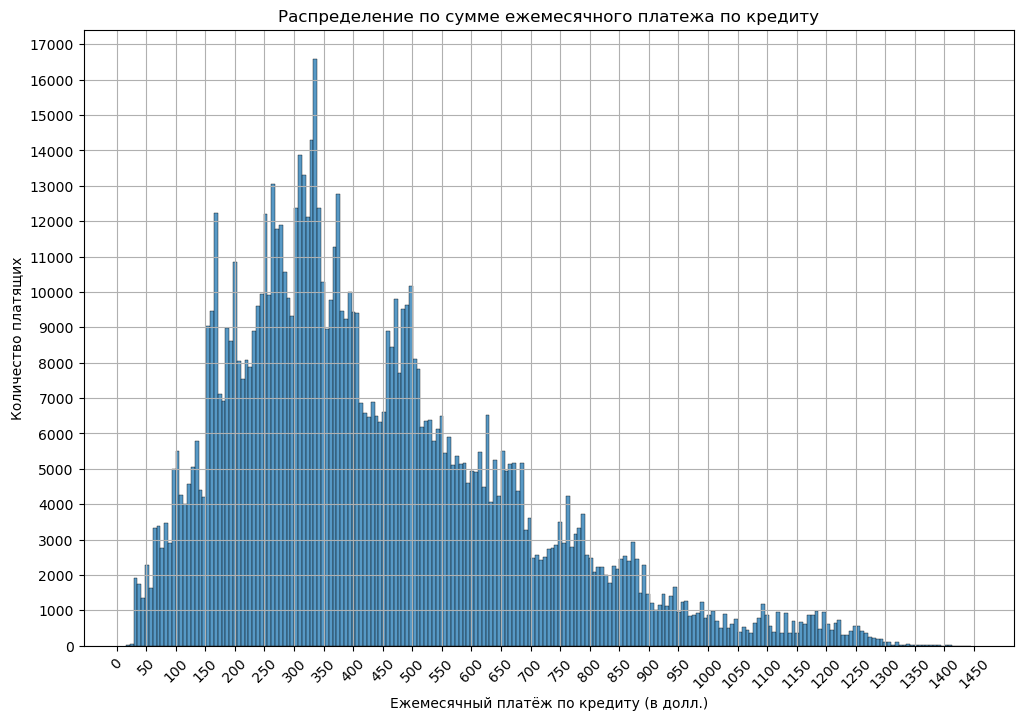

In [18]:
plt.figure(figsize=(12, 8))
sns.histplot(data=loans, x="installment")
plt.title("Распределение по сумме ежемесячного платежа по кредиту")
plt.xlabel("Ежемесячный платёж по кредиту (в долл.)")
plt.xticks(np.arange(0, 1500, 50), rotation=45)
plt.ylabel("Количество платящих")
plt.yticks(np.arange(0, 17001, 1000))
plt.grid()
plt.show()

График по ежемесячным платежам повторяет тенденцию графика по процентным ставкам кредита: хвост в правой части с большими суммами платежа и смещённый центр с медианными значениями в районе 330-340 долларов в месяц, что свидетельствует о том, что большинство заёмщиков вносят платежи среднего размера, но в то же время существуют те, кто выплачивает более крупные суммы.

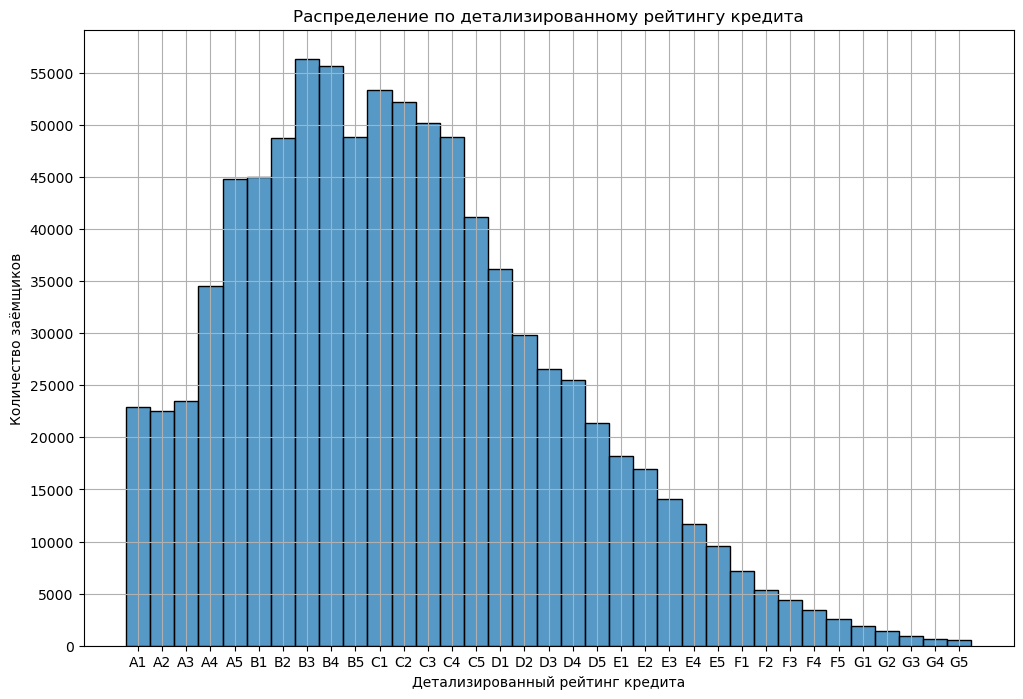

In [19]:
plt.figure(figsize=(12, 8))
sns.histplot(data=loans.sort_values("sub_grade"), x="sub_grade")
plt.title("Распределение по детализированному рейтингу кредита")
plt.xlabel("Детализированный рейтинг кредита")
plt.ylabel("Количество заёмщиков")
plt.yticks(np.arange(0, 60000, 5000))
plt.grid()
plt.show()

Кредитный рейтинг заёмщиков визуально связан с графиками по процентной ставке и ежемесячными платежами по кредиту: график смещён в сторону высоких грейдов.

На гистограмме видно, как основная масса заёмщиков лежит в диапазоне от максимальной (А) до средней (С) надёжности по риску, с подавляющим большинством вокруг высокого уровня надёжности (В). Следовательно, банк в основной массе выдаёт кредиты клиентам, в финансовом состоянии которых он уверен и старается выдавать меньше кредитов клиентам с высокими рисками по дефолту.

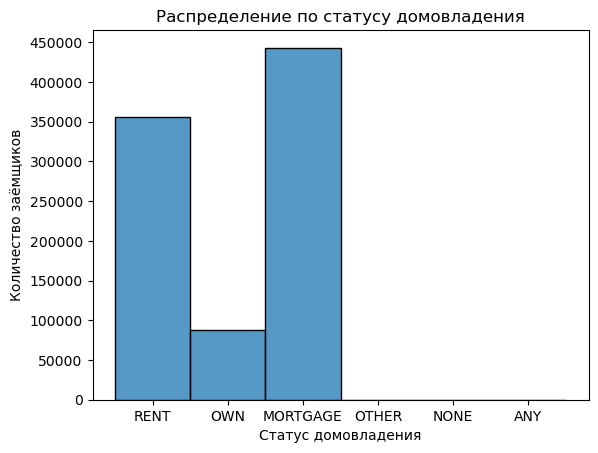

In [20]:
sns.histplot(data=loans, x="home_ownership")
plt.title("Распределение по статусу домовладения")
plt.xlabel("Статус домовладения")
plt.ylabel("Количество заёмщиков")
plt.yticks(np.arange(0, 500000, 50000))
plt.show()

Гистограмма показывает, что подавляющее большинство заёмщиков имеют в собственности недвижимость в ипотеку, за ними по популярности следует арендующие жильё заёмщики, и собственники недвижимого имущества.

##### 5.2. Приведём основную статистику для поля ‘loan_amnt’

In [21]:
loans["loan_amnt"].describe()

count    886868.000000
mean      14752.593452
std        8434.363707
min         500.000000
25%        8000.000000
50%       13000.000000
75%       20000.000000
max       35000.000000
Name: loan_amnt, dtype: float64

In [22]:
print("Максимальное и минимальное значения: \nmax: ", loans["loan_amnt"].describe().loc["max"], "\nmin:", loans["loan_amnt"].describe().loc["min"])
print("Среднее значение:", loans["loan_amnt"].describe().loc["mean"].round(2))
print("Медианное значение:", loans["loan_amnt"].describe().loc["50%"])
print("Стандартное отклонение:", loans["loan_amnt"].describe().loc["std"].round(2))
print("Квантиль уровня 1%:", loans["loan_amnt"].quantile(0.01))
print("Квантиль уровня 5%:", loans["loan_amnt"].quantile(0.05))
print("Квантиль уровня 95%:", loans["loan_amnt"].quantile(0.95))
print("Квантиль уровня 99%:", loans["loan_amnt"].quantile(0.99))

Максимальное и минимальное значения: 
max:  35000.0 
min: 500.0
Среднее значение: 14752.59
Медианное значение: 13000.0
Стандартное отклонение: 8434.36
Квантиль уровня 1%: 1800.0
Квантиль уровня 5%: 3600.0
Квантиль уровня 95%: 32000.0
Квантиль уровня 99%: 35000.0


Вопрос: каково медианное значение для поля `loan_amnt`?

_**Ответ на вопрос**_: **$13000**

##### 5.3. Выводы по статистике поля ‘loan_amnt’ (указанная сумма кредита):

Среднее значение больше медианы, распределение смещено в сторону более высоких значений. 90% (5 и 95 квантили) клиентской базы распределены в диапазоне между $3600 и $32000, а межквартильный размах (IQR) – $8000 - $20000.

##### 5.4. Построим boxplot для полей ‘loan_amnt’, ‘installment’, ‘int_rate’. 
Визуально оценим, как распределены значения сумм кредита, ежемесячных платежей и процентных ставок у заёмщиков.

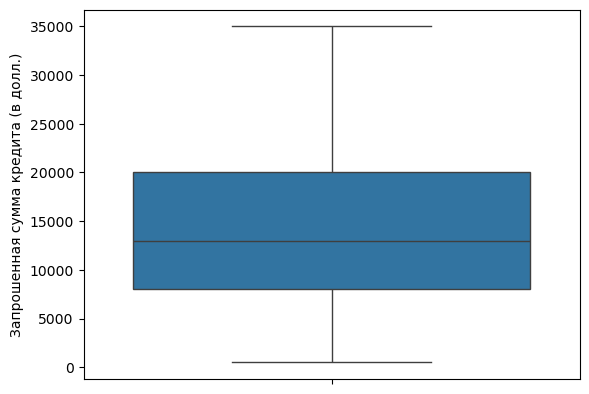

In [23]:
sns.boxplot(data=loans, y="loan_amnt")
plt.ylabel("Запрошенная сумма кредита (в долл.)")
plt.show()

Вопрос: Выбери верное утверждение для поля `loan_amnt`.

_**Ответ на вопрос**_: Среднее значение больше медианы, распределение смещено в сторону более высоких значений.

Вопрос: Выбери верное утверждение.

_**Ответ на вопрос**_: Для `loan_amnt` не наблюдается существенное количество выбросов.

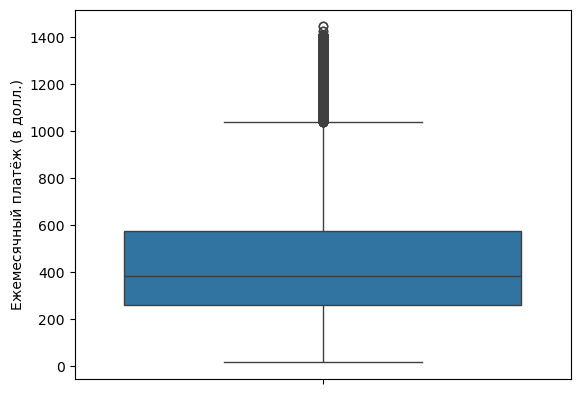

In [24]:
sns.boxplot(data=loans, y="installment")
plt.ylabel("Ежемесячный платёж (в долл.)")
plt.show()

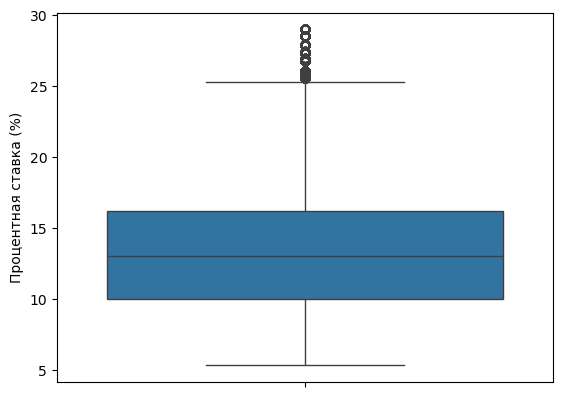

In [25]:
sns.boxplot(data=loans, y="int_rate")
plt.ylabel("Процентная ставка (%)")
plt.show()

У всех трёх графиков заметна правосторонняя ассиметрия. На графиках по ежемесячному платежу и процентной ставке есть выбросы в крупных значениях, что свидетельствует о более высоких ежемесячных платежах и процентных ставок для небольшого количества займов. Причём в ежемесячных платежах выбросы представлены в большом количестве.

Основная масса данных сосредоточена в нижней части графика, что указывает на ассиметрию в распределении значений. Т.е. меньшие значения (как для ежемесячных платежей, так и для процентных ставок по кредитам) встречаются чаще чем более высокие.

##### 5.5. Оценим распределение числовых переменных относительно статуса займа (‘loan_status’).
Построим графики boxplot для следующих полей:

        - ‘int_rate’.
        - ‘dti’.
        - ‘loan_amnt’.

In [26]:
loans["loan_status"].value_counts()

loan_status
Current                                                601338
Fully Paid                                             207722
Charged Off                                             45248
Late (31-120 days)                                      11589
Issued                                                   8396
In Grace Period                                          6250
Late (16-30 days)                                        2357
Does not meet the credit policy. Status:Fully Paid       1988
Default                                                  1219
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

In [27]:
status_order = loans["loan_status"].value_counts().index

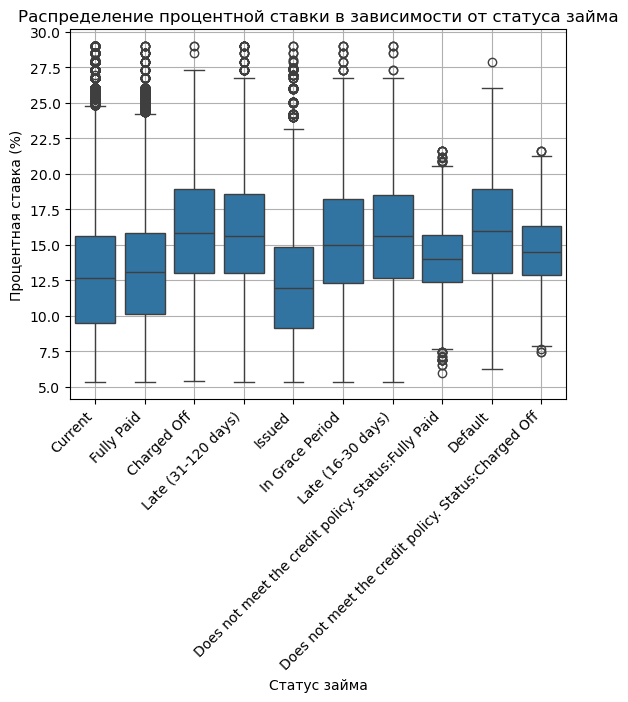

In [28]:
sns.boxplot(data=loans, x="loan_status", y="int_rate", order=status_order)
plt.title("Распределение процентной ставки в зависимости от статуса займа")
plt.ylabel("Процентная ставка (%)")
plt.yticks(np.arange(5, 31, 2.5))
plt.xlabel("Статус займа")
plt.xticks(rotation=45, ha="right")
plt.grid()
plt.show()

 Судя по графику, медиана процентной ставки по положительным статусам займа ('Current', 'Fully Paid', 'Issued', 'Does not meet the credit policy. Status:Fully Paid') лежит ниже (от 11 до 14 п.п.) рисковых и убыточных ('Late (31-120 days)', 'In Grace Period', 'Late (16-30 days)' и 'Charged Off', 'Default', 'Does not meet the credit policy. Status:Charged Off'). Возможно, в политике банка есть правило, по которому кредитам с негативными статусами займа повышают процентную ставку вследствие рискованной сделки, или если у клиента высокая ставка, он может не справляться с долговой нагрузкой, следовательно выходить в дефолт.
 
 Меньший размах у ящиков, визуализирующих исторические данные (с припиской 'Does not meet the credit policy'), может говорить о меньшем количестве выданных кредитов в прошлом или менее гибкой политике по кредитной ставке.

Вопрос: Выбери верное утверждение.

_**Ответ на вопрос**_: Средняя ставка кредитов в дефотле (Default) больше, чем ставка погашенных кредитов (Fully Paid).

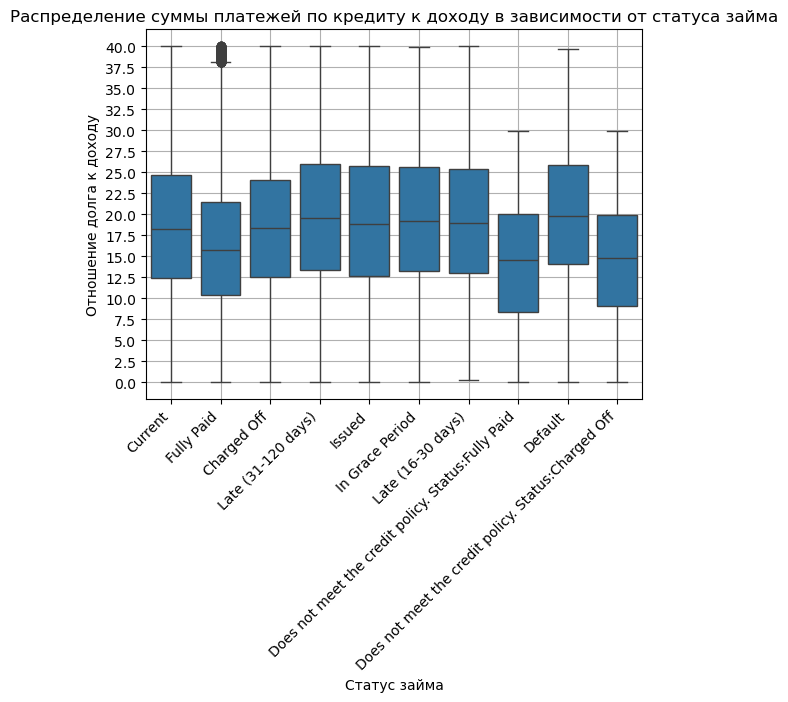

In [29]:
sns.boxplot(data=loans, x="loan_status", y="dti", order=status_order)
plt.title("Распределение суммы платежей по кредиту к доходу в зависимости от статуса займа")
plt.ylabel("Отношение долга к доходу")
plt.yticks(np.arange(0, 41, 2.5))
plt.xlabel("Статус займа")
plt.xticks(rotation=45, ha="right")
plt.grid()
plt.show()

Графики не показывают сильных различий по отношению долга к займам со статусом займа в нынешнее время. Визуально заметны отличия между историческими и текущими данными, где медиана лежит ниже и размах данных меньше, скорее всего, в виду меньшей закредитованности населения в прошлом. 

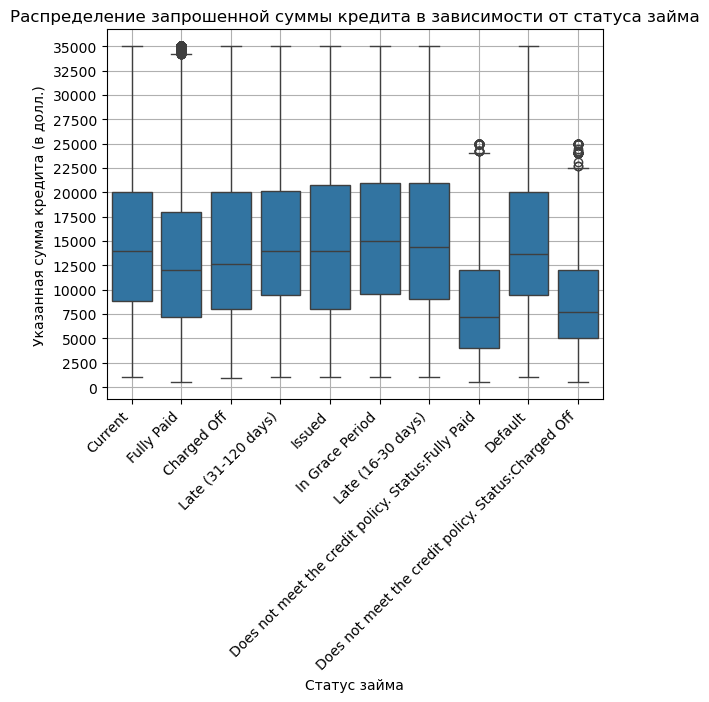

In [30]:
sns.boxplot(data=loans, x="loan_status", y="loan_amnt", order=status_order)
plt.title("Распределение запрошенной суммы кредита в зависимости от статуса займа")
plt.ylabel("Указанная сумма кредита (в долл.)")
plt.yticks(np.arange(0, 35001, 2500))
plt.xlabel("Статус займа")
plt.xticks(rotation=45, ha="right")
plt.grid()
plt.show()

Согласно визуализации, кредиты с историческими данными выдавались на сильно меньшую сумму (примерно до 10000 долларов ниже), что, вероятно, иллюстрирует инфляцию доллара. Некоторые клиентов с экстремально большими по процентными ставками, отношением суммы долга к доходу и суммой кредита, несмотря на рисковость этих факторов в совокупности, сумели выплатить кредит.

##### 5.7. Пострим график barplot для среднего значения ‘annual_inc’ по ‘loan_status’.

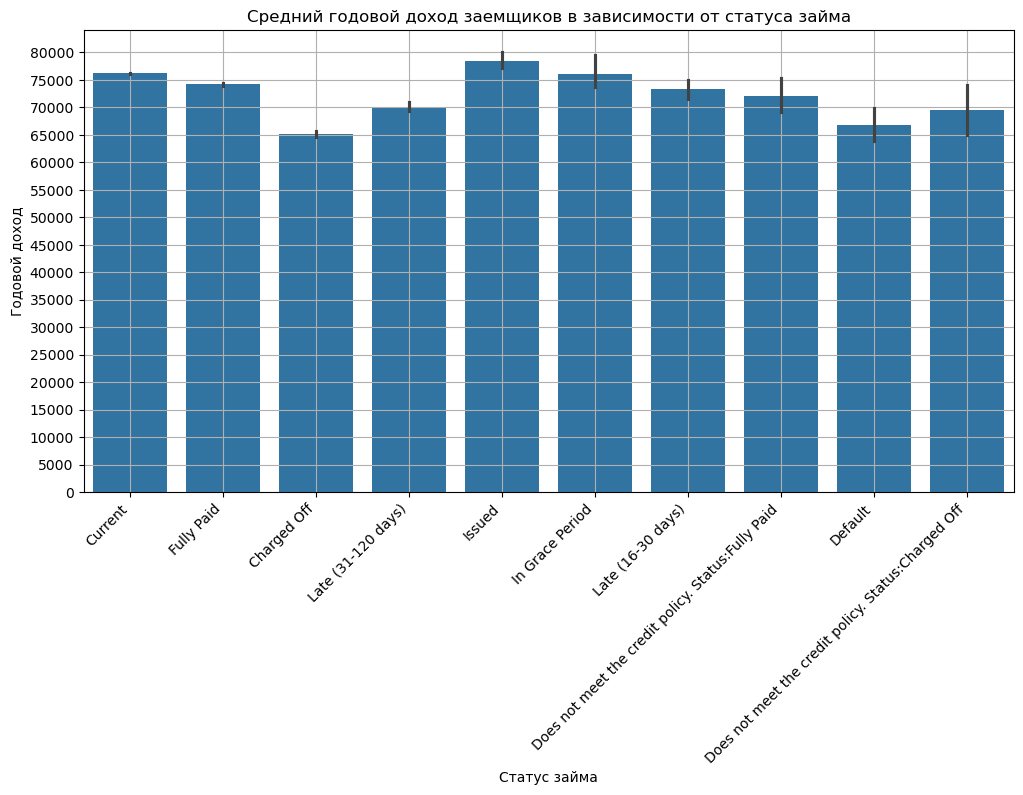

In [31]:
plt.figure(figsize=(12, 6))
sns.barplot(data=loans, x="loan_status", y="annual_inc", order=status_order)
plt.title("Средний годовой доход заемщиков в зависимости от статуса займа")
plt.ylabel("Годовой доход")
plt.yticks(np.arange(0, 80001, 5000))
plt.xlabel("Статус займа")
plt.xticks(rotation=45, ha="right")
plt.grid()
plt.show()

Клиенты с более высоким средним годовым доходом менее склонны к просрочкам по кредитным платежам. Клиенты с относительно низким доходом попали в убыточные для банка сделки по кредитам ('Charged Off', 'Late (31-120 days)', 'Default').

Вопрос: Выбери верное утверждение.

_**Ответ на вопрос**_: Средний доход, указанный в дефолтной кредитной заявке (Default) меньше, чем средний доход погашенных кредитов (Fully Paid).

##### 5.8. Оценим корреляцию между полями ['int_rate', 'loan_amnt', 'total_pymnt', 'total_acc'].

In [32]:
corr_cols = ["int_rate", "loan_amnt", "total_pymnt", "total_acc"]

In [33]:
corr_matrix = loans[corr_cols].corr().round(3)
corr_matrix

,int_rate,loan_amnt,total_pymnt,total_acc
int_rate,1.000,0.145,0.171,-0.039
loan_amnt,0.145,1.000,0.475,0.223
total_pymnt,0.171,0.475,1.000,0.109
total_acc,-0.039,0.223,0.109,1.000


Наибольшая корреляция у суммы кредита (‘loan_amnt’) и выплаченной сумме (‘total_pymnt’), равная 0.475, что свидетельствует об умеренной положительной связи, так как общая сумма платежей по полностью выплаченной ссуде зависит от  её изначального размера. Наименьшая у процентной ставки с количеством выданных кредитов, следовательно, количество кредитов не влияет на процентную ставку.

Вопрос: Укажите пару наиболее коррелирующих полей.

_**Ответ на вопрос**_: `total_pymnt` + `loan_amnt`

##### 5.11. Визуализируем. 

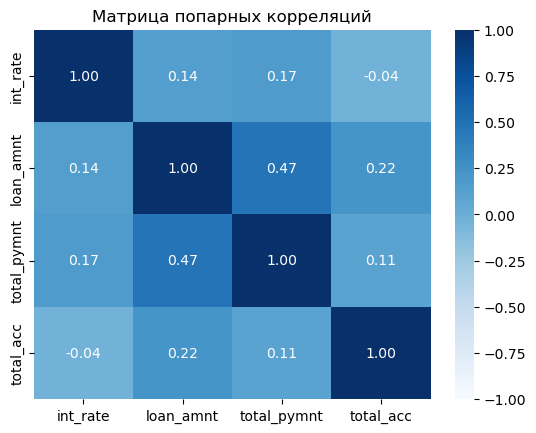

In [34]:
sns.heatmap(data=corr_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Матрица попарных корреляций")
plt.show()

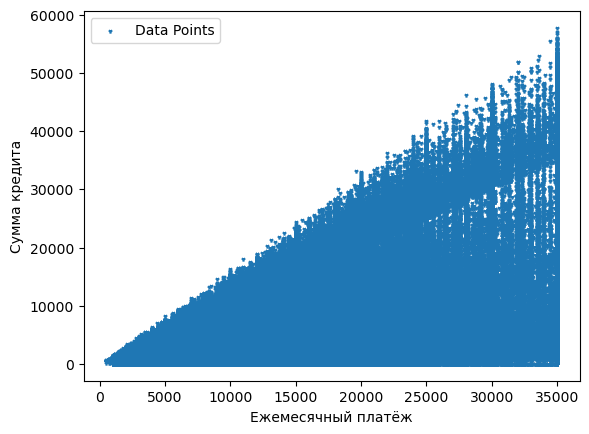

In [35]:
x = loans["loan_amnt"]
y = loans["total_pymnt"]

plt.scatter(x, y, s=10, marker="1", label="Data Points")
plt.xlabel("Ежемесячный платёж")
plt.ylabel("Сумма кредита")
plt.legend()
plt.show()

## Итоги EDA.
1. Проверили типы заявок и исключили данные с созаёмщиками (заявки типа JOINT). Удалили колонки с долей пропусков >= 20%.
2. Убрали признаки с почти отсутствующей вариативностью.
3. Построили распределения запрошенной суммы кредита, фактической суммы, ставки, ежемесячного платежа, рейтинга и статуса жилья.
4. Для `loan_amnt` рассчитали min/max, среднее, медиану, σ и квантили; построили box plot. Медиана $13000; существенных выбросов не выявлено.
Фактическая сумма кредита сопоставима с запрошенной.
5. Сопоставили ставку, долговую нагрузку, платеж и доход для погашенных
и дефолтных кредитов. Как правило, у клиентов, вышедших в дефолт, выше процентная ставка и ниже доход чем в среднем у тех, кто погашает кредит.
6. Построили матрицу корреляций и совместное распределение наиболее связанных признаков `total_pymnt` + `loan_amnt`. Отсутствие строгого визуального тренда
тоже является результатом анализа.